### Bài thực hành số 4: Phát hiện giao dịch gian lận

Giới thiệu về Dataset:
Bộ dữ liệu IBM Transactions for Anti-Money Laundering (AML) do IBM Research phát triển nhằm giải quyết bài toán thiếu hụt dữ liệu chuẩn (benchmark) trong nghiên cứu phòng chống rửa tiền. Do rào cản bảo mật ngân hàng và quy định quyền riêng tư (GDPR), dữ liệu giao dịch tài chính thật không thể công khai. IBM đã sử dụng các mô phỏng đa tác tử (Multi-Agent Simulation) để tạo ra tập dữ liệu tổng hợp (Synthetic Data) mô phỏng các hành vi giao dịch ngân hàng phục vụ nghiên cứu; độ sát với dữ liệu thực vẫn cần được đánh giá.

Tệp HI-Small_Trans.csv là phiên bản quy mô nhỏ thuộc dòng tệp HI (**Higher Illicit** — tỷ lệ giao dịch rửa tiền cao hơn nhóm LI), theo [Altman và cộng sự, NeurIPS 2023, bảng 2 và 4](https://papers.neurips.cc/paper_files/paper/2023/file/5f38404edff6f3f642d6fa5892479c42-Paper-Datasets_and_Benchmarks.pdf)
+ Quy mô: Khoảng 5 triệu dòng giao dịch (dung lượng chưa nén khoảng 500 MB – 600 MB), vừa đủ gọn để chạy thực hành trên các máy trạm cá nhân hoặc cụm Spark nhỏ.
+ Cấu trúc ma trận mạng: Hàng trăm nghìn tài khoản (Accounts) tạo thành một Đồ thị Hướng Đa cạnh (Directed Multigraph), trong đó 2 tài khoản có thể thực hiện nhiều giao dịch ở các thời điểm khác nhau.

Cấu trúc dữ liệu:
Timestamp: Thời gian thực hiện giao dịch (yyyy/MM/dd HH:mm), dùng để xác định tính tuần tự thời gian giữa các nấc rửa tiền (Temporal Ordering).

From Bank: Mã định danh ngân hàng gửi.

Account ở vị trí thứ 3 trong CSV (Spark thường tự đổi thành Account2): Mã định danh tài khoản nguồn (src), đóng vai trò nút nguồn trên đồ thị.

To Bank: Mã định danh ngân hàng nhận.

Account ở vị trí thứ 5 trong CSV (Spark thường tự đổi thành Account4): Mã định danh tài khoản đích (dst), đóng vai trò nút đích trên đồ thị.

Amount Received: Số tiền tài khoản nhận thực tế thu về (sau khi quy đổi hoặc trừ phí).

Receiving Currency: Loại tiền tệ tài khoản nhận thu về.

Amount Paid: Số tiền tài khoản gửi chuyển đi, đặc trưng quan trọng để phát hiện hành vi chia nhỏ số tiền (Structuring).

Payment Currency: Loại tiền tệ dùng khi chuyển đi.

Payment Format: Phương thức thanh toán (ACH, Wire, Cheque, Credit Card, Cash), giúp nhận diện kênh giao dịch có rủi ro cao.

Is Laundering: Nhãn thực tế (Target Label) với 0 là giao dịch hợp lệ và 1 là giao dịch rửa tiền.

+ File dữ liệu thực hành: https://www.kaggle.com/datasets/ealtman2019/ibm-transactions-for-anti-money-laundering-aml?resource=download&select=HI-Small_Trans.csv

### Kết quả chính — lần chạy toàn bộ ngày 29/10/2026
Đã xử lý **5.078.345** giao dịch hợp lệ, gồm **5.177** nhãn rửa tiền.
Tập test theo thời gian có **1.012.925** giao dịch và **1.792** nhãn dương.
Ngưỡng của từng mô hình được chọn bằng F1 trên validation trước khi đánh giá test.

| Mô hình | Ngưỡng | Accuracy | ROC-AUC | PR-AUC | Precision lớp 1 | Recall lớp 1 | F1 lớp 1 |
|---|---:|---:|---:|---:|---:|---:|---:|
| Thuộc tính giao dịch | 0,8 | 96,1309% | 0,935333 | 0,062245 | 3,1353% | 69,8103% | 0,060010 |
| Giao dịch + đồ thị lịch sử | 0,9 | 98,4064% | 0,965196 | 0,038593 | 4,4329% | 38,9509% | 0,079599 |

Đồ thị giảm cảnh báo sai từ **38.650** xuống **15.048**, nhưng số giao dịch rửa tiền phát hiện được cũng giảm từ **1.251** xuống **698**.
ROC-AUC/F1 tăng còn PR-AUC/recall giảm: chưa có mô hình tốt hơn trên mọi tiêu chí.
Baseline luôn đoán bình thường đạt accuracy **99,8231%**, nhưng không phát hiện rửa tiền.

Đã chạy đủ **20 ô mã** và kiểm tra lưu/nạp trên **31 giao dịch**, gồm tài khoản mới: không sai khác xác suất hoặc nhãn.


## Lời giải — 4 bài tập
**Dữ liệu:** [IBM AML, phiên bản Kaggle 8, HI-Small_Trans.csv](https://www.kaggle.com/datasets/ealtman2019/ibm-transactions-for-anti-money-laundering-aml?select=HI-Small_Trans.csv).
**Môi trường:** Python 3.12, Java 21, Spark 4.0.2, GraphFrames 0.12.3; xem `requirements.txt`.
Notebook mặc định đọc toàn bộ tệp; `AML_FRACTION=0.02` là chế độ kiểm tra trên mẫu 2%, có ghi rõ phạm vi trong output.
Lấy mẫu cạnh làm mất cấu trúc mạng nên kết quả trên mẫu **không đại diện** chất lượng phát hiện trên toàn đồ thị.

### Giả định
- Một nút là **cặp (ngân hàng, tài khoản)**. Dùng JSON struct để tránh va chạm khi nối chuỗi.
- Fan-in/mule/layering là dấu hiệu để điều tra, không là kết luận một giao dịch đã rửa tiền.
- Chỉ so sánh số tiền có cùng tiền tệ; không cộng USD với EUR hoặc tiền tệ khác.
- Ngưỡng số tiền/thời gian dưới đây là tham số minh họa của bài, không phải ngưỡng pháp lý.
- Motif trên toàn dữ liệu phục vụ mô tả. Phần dự đoán dùng một snapshot quá khứ riêng để tránh nhìn trước tương lai.

### Thông tin đối chiếu lần chạy đầy đủ
Môi trường lần chạy: Python 3.12.16, Java 21, Spark 4.0.2, GraphFrames 0.12.3.
Nguồn: `HI-Small_Trans.csv`, Kaggle phiên bản 8, 475,664,283 byte.
SHA-256: `b19d39f515523373f991b689c07e11e7b0b95c17a2c27a87d91584ae16c5b040`.

Chuẩn bị môi trường Spark

In [1]:
import os, csv
from pathlib import Path
ROOT=Path.cwd().resolve()
if ROOT.name=='loi_giai': ROOT=ROOT.parent
os.chdir(ROOT)
import sys
os.environ['PYSPARK_PYTHON'] = sys.executable
os.environ.setdefault('SPARK_LOCAL_IP','127.0.0.1')
from pyspark.sql import SparkSession, functions as F
from graphframes import GraphFrame
from pyspark import StorageLevel
sys.path.insert(0, str(ROOT/'loi_giai'))
from aml_model import attach_history as join_history, save_aml_bundle, load_aml_bundle
# Shuffle trên đĩa; /tmp có thể là tmpfs nhỏ.
os.environ.setdefault('SPARK_LOCAL_DIRS', str(ROOT/'.work/spark'))
Path(os.environ['SPARK_LOCAL_DIRS']).mkdir(parents=True, exist_ok=True)
spark=(SparkSession.builder.master(os.environ.get('AML_SPARK_MASTER','local[4]')).appName('IBM_AML_Solutions')
    .config('spark.driver.memory',os.environ.get('AML_DRIVER_MEMORY','5g'))
    .config('spark.sql.shuffle.partitions',os.environ.get('AML_SHUFFLE_PARTITIONS','32'))
    .config('spark.sql.session.timeZone','UTC').config('spark.ui.enabled','false').config('spark.ui.showConsoleProgress','false')
    .config('spark.jars.packages','io.graphframes:graphframes-spark4_2.13:0.12.3')
    .getOrCreate())
spark.sparkContext.setLogLevel('ERROR')
spark.sparkContext.setCheckpointDir(str(ROOT/'loi_giai/checkpoints'))
AML_FRACTION=float(os.environ.get('AML_FRACTION','1.0'))
assert 0 < AML_FRACTION <= 1

:: loading settings :: url = jar:file:/home/kent/KentProject/BaiTapPhanTichDuLieuLon/BaiTapMonPhanTichKhaiPhaDuLieuLon/.venv-labs/lib/python3.12/site-packages/pyspark/jars/ivy-2.5.3.jar!/org/apache/ivy/core/settings/ivysettings.xml
Ivy Default Cache set to: /home/kent/.ivy2.5.2/cache
The jars for the packages stored in: /home/kent/.ivy2.5.2/jars
io.graphframes#graphframes-spark4_2.13 added as a dependency
:: resolving dependencies :: org.apache.spark#spark-submit-parent-dfb7310d-2962-453e-9016-9c134a2ccd4f;1.0
	confs: [default]
	found io.graphframes#graphframes-spark4_2.13;0.12.3 in central
	found io.graphframes#graphframes-graphx-spark4_2.13;0.12.3 in central
	found org.apache.datasketches#datasketches-java;6.2.0 in central


	found org.apache.datasketches#datasketches-memory;3.0.2 in central
:: resolution report :: resolve 149ms :: artifacts dl 4ms
	:: modules in use:
	io.graphframes#graphframes-graphx-spark4_2.13;0.12.3 from central in [default]
	io.graphframes#graphframes-spark4_2.13;0.12.3 from central in [default]
	org.apache.datasketches#datasketches-java;6.2.0 from central in [default]
	org.apache.datasketches#datasketches-memory;3.0.2 from central in [default]
	---------------------------------------------------------------------
	|                  |            modules            ||   artifacts   |
	|       conf       | number| search|dwnlded|evicted|| number|dwnlded|
	---------------------------------------------------------------------
	|      default     |   4   |   0   |   0   |   0   ||   4   |   0   |
	---------------------------------------------------------------------
:: retrieving :: org.apache.spark#spark-submit-parent-dfb7310d-2962-453e-9016-9c134a2ccd4f
	confs: [default]
	0 artifacts c

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


Bước 1: Chuẩn bị dữ liệu và Khởi tạo GraphFrame
Đồ thị trong GraphFrames yêu cầu 2 DataFrame chính:
Vertices (Đỉnh): Danh sách các tài khoản ngân hàng, phải có cột định danh duy nhất là id.
Edges (Cạnh): Danh sách các giao dịch, phải có cột nguồn src (tài khoản gửi) và cột đích dst (tài khoản nhận), kèm các thuộc tính như amount, timestamp.

In [2]:
from pyspark.sql.types import StructType, StructField, StringType
from pyspark import StorageLevel
DATA_PATH=Path(os.environ.get('AML_PATH',str(ROOT/'aml_data/HI-Small_Trans.csv')))
if not DATA_PATH.exists():
    raise FileNotFoundError('Tải HI-Small_Trans.csv từ nguồn ở đầu notebook và đặt vào aml_data/.')
# CSV IBM có hai cột cùng tên Account. Dùng vị trí cột để phân biệt,
# không dựa vào tên Account2/Account4 do một số bộ đọc tự sinh ra.
with DATA_PATH.open(newline='',encoding='utf-8-sig') as f:
    header=next(csv.reader(f))
expected=['Timestamp','From Bank','Account','To Bank','Account','Amount Received','Receiving Currency','Amount Paid','Payment Currency','Payment Format','Is Laundering']
normalized_header=header.copy()
if len(normalized_header)==11:
    if normalized_header[2]=='Account2': normalized_header[2]='Account'
    if normalized_header[4]=='Account4': normalized_header[4]='Account'
if normalized_header != expected:
    raise ValueError(f'Schema CSV ngoài dự kiến: {header}')
names=['timestamp_text','from_bank','from_account','to_bank','to_account','amount_received_text','receiving_currency','amount_paid_text','payment_currency','payment_format','label_text']
# Đọc theo vị trí với tên không trùng; mã tài khoản giữ kiểu chuỗi, không mất số 0 đầu.
schema=StructType([StructField(c,StringType(),True) for c in names])
df_tx_full=(spark.read.option('header',True).option('enforceSchema',True).schema(schema).csv(str(DATA_PATH)))
df_tx=df_tx_full if AML_FRACTION==1 else df_tx_full.sample(False,AML_FRACTION,seed=42)
df_tx=df_tx.dropna(subset=['from_bank','to_bank','from_account','to_account'])
edges=(df_tx.select(
    F.to_json(F.struct(F.col('from_bank').alias('bank'),F.col('from_account').alias('account'))).alias('src'),
    F.to_json(F.struct(F.col('to_bank').alias('bank'),F.col('to_account').alias('account'))).alias('dst'),
    'from_bank','to_bank',
    F.col('amount_paid_text').cast('double').alias('amount'),
    F.col('amount_received_text').cast('double').alias('amount_received'),
    F.to_timestamp('timestamp_text','yyyy/MM/dd HH:mm').alias('timestamp'),
    'receiving_currency','payment_currency','payment_format',
    F.col('label_text').cast('int').alias('is_laundering'))
    .dropna(subset=['timestamp','amount','amount_received','src','dst','payment_currency','receiving_currency','payment_format','is_laundering'])
    .filter((F.col('amount')>0)&(F.col('amount_received')>0)&F.col('is_laundering').isin(0,1))
    .filter(F.col('from_bank').isNotNull() & F.col('to_bank').isNotNull())
    .persist(StorageLevel.MEMORY_AND_DISK))
vertices=edges.select(F.col('src').alias('id')).union(edges.select(F.col('dst').alias('id'))).distinct()
g=GraphFrame(vertices,edges)
# Các motif đều loại tự chuyển; đẩy điều kiện này xuống trước mọi phép ghép.
motif_graph=GraphFrame(vertices,edges.filter(F.col('src')!=F.col('dst')))
print('Nguồn:',DATA_PATH.name,'| tỷ lệ mẫu:',AML_FRACTION,'| giao dịch hợp lệ:',edges.count())
edges.groupBy('is_laundering').count().orderBy('is_laundering').show()
vertices.show(3,truncate=False)

Nguồn: HI-Small_Trans.csv | tỷ lệ mẫu: 1.0 | giao dịch hợp lệ: 5078345


+-------------+-------+
|is_laundering|  count|
+-------------+-------+
|            0|5073168|
|            1|   5177|
+-------------+-------+



+---------------------------------------+
|id                                     |
+---------------------------------------+
|{"bank":"010","account":"80012FD90"}   |
|{"bank":"00908","account":"8005FB700"} |
|{"bank":"021611","account":"800AC9010"}|
+---------------------------------------+
only showing top 3 rows


Bước 2: Phát hiện mô hình gian lận bằng Motif Finding
Motif Finding cho phép tìm kiếm các đường đi/mô hình giao dịch bất thường bằng cú pháp khớp chuỗi (DSL).
A. Phát hiện vòng tròn giao dịch (Round-Tripping / Ring Fraud)
Tiền được chuyển lòng vòng qua các tài khoản trung gian để xóa vết (A → B → C → A):

In [3]:
cycles=(motif_graph.find('(a)-[e1]->(b); (b)-[e2]->(c); (c)-[e3]->(a)')
    .filter('a.id != b.id AND b.id != c.id AND a.id != c.id')
    .filter('e2.timestamp >= e1.timestamp AND e3.timestamp >= e2.timestamp'))
cycles.select(F.col('a.id').alias('a'),F.col('b.id').alias('b'),F.col('c.id').alias('c'),
    F.col('e1.amount').alias('amount1'),F.col('e2.amount').alias('amount2'),F.col('e3.amount').alias('amount3')).show(10,truncate=35)

+-----------------------------------+-----------------------------------+-----------------------------------+--------+--------+---------+
|                                  a|                                  b|                                  c| amount1| amount2|  amount3|
+-----------------------------------+-----------------------------------+-----------------------------------+--------+--------+---------+
|{"bank":"017769","account":"8084...|{"bank":"0117999","account":"808...|{"bank":"0012461","account":"808...| 4025.91| 3598.77|  1620.91|
|{"bank":"009129","account":"811D...|{"bank":"029685","account":"811D...|{"bank":"0015747","account":"811...|   174.9|   53.54|  1579.48|
|{"bank":"0016649","account":"806...|{"bank":"0217096","account":"806...|{"bank":"004","account":"80645B8...|39184.06|225197.1|253617.87|
|{"bank":"0238744","account":"810...|{"bank":"0042810","account":"810...|{"bank":"0210404","account":"810...| 4893.86| 4467.24|  4932.03|
|{"bank":"0032375","account":"80B.

B. Phát hiện mô hình gom tiền hoặc phân tán tiền (Scatter-Gather / Smurfing)
Một tài khoản nhận tiền từ nhiều tài khoản khác nhau trong thời gian ngắn, sau đó chuyển toàn bộ sang một tài khoản đích duy nhất:

Để khớp mô tả chuyển gần toàn bộ tiền gom được, hai khoản nhận phải cùng tiền tệ với khoản chuyển ra; tiền chuyển tiếp bằng 95%–100% tổng hai khoản nhận. Chỉ có liên kết và thứ tự thời gian sẽ tạo cảnh báo quá rộng. Cấu hình này xét hai nguồn một lần, chưa bao quát trường hợp gom từ nhiều hơn hai nguồn rồi chuyển tổng; phần fan-in bên dưới xử lý dấu hiệu nhiều nguồn.

In [4]:
# Ghép cạnh vào/ra trước để áp dụng giới hạn 2 giờ trước khi ghép nguồn thứ hai.
# Phá đối xứng a,b bằng a.id < b.id để mỗi cặp nguồn chỉ xét một lần.
smurfing=(motif_graph.find('(a)-[e1]->(c); (c)-[e3]->(d); (b)-[e2]->(c)')
    .filter('a.id < b.id AND a.id != c.id AND b.id != c.id AND c.id != d.id AND a.id != d.id AND b.id != d.id')
    .filter('e3.timestamp >= e1.timestamp AND e3.timestamp >= e2.timestamp')
    .filter('e3.timestamp < e1.timestamp + INTERVAL 2 HOURS AND e3.timestamp < e2.timestamp + INTERVAL 2 HOURS')
    .filter('e1.receiving_currency = e2.receiving_currency AND e1.receiving_currency = e3.payment_currency')
    .filter('e3.amount >= 0.95*(e1.amount_received+e2.amount_received) AND e3.amount <= e1.amount_received+e2.amount_received'))
smurfing.select(F.col('a.id').alias('a'),F.col('b.id').alias('b'),F.col('c.id').alias('c'),F.col('d.id').alias('d')).show(10,truncate=35)

+-----------------------------------+-----------------------------------+-----------------------------------+-----------------------------------+
|                                  a|                                  b|                                  c|                                  d|
+-----------------------------------+-----------------------------------+-----------------------------------+-----------------------------------+
|{"bank":"0015768","account":"812...|{"bank":"002053","account":"8123...|{"bank":"015980","account":"8123...|{"bank":"0022732","account":"812...|
|{"bank":"0024779","account":"809...|{"bank":"0024779","account":"809...|{"bank":"0025202","account":"809...|{"bank":"0126190","account":"809...|
|{"bank":"003","account":"804A25C...|{"bank":"003","account":"804A25D...|{"bank":"012","account":"804A25C...|{"bank":"007","account":"804EF57...|
|{"bank":"0014804","account":"812...|{"bank":"003144","account":"8123...|{"bank":"015980","account":"8123...|{"bank":"002273

Bài tập 1: Dạng Fan-In (Gom tiền từ nhiều tài khoản nhỏ về 1 tài khoản tập trung)
Mô tả hành vi: Nhiều tài khoản phụ (Smurfs) thực hiện chuyển các khoản tiền nhỏ rải rác về cùng một tài khoản đích duy nhất trong một khoảng thời gian ngắn để gom thành một khoản tiền lớn.

### Lời giải bài 1 — Fan-in
Tính cửa sổ 1 giờ trượt mỗi 10 phút, nhóm theo tài khoản nhận và tiền tệ nhận.
Một cảnh báo cần ít nhất 5 người gửi **khác nhau**, mỗi khoản nhận không quá 10.000 đơn vị tiền tệ và tổng ít nhất 20.000.
Loại tự chuyển để không tính hoạt động nội bộ là nhiều nguồn. Tiền tệ được giữ trong khóa nhóm nên tổng luôn có cùng đơn vị.
Cửa sổ trượt có thể chồng lặp; cùng một giao dịch có thể xuất hiện trong nhiều cảnh báo, không cộng số cảnh báo thành số giao dịch rửa tiền.

In [5]:
MIN_SENDERS=5
SMALL_AMOUNT_MAX=10000.0
FANIN_TOTAL_MIN=20000.0
fan_in_candidates=(edges.filter((F.col('src')!=F.col('dst')) & (F.col('amount_received')<=SMALL_AMOUNT_MAX))
    .groupBy('dst','receiving_currency',F.window('timestamp','1 hour','10 minutes'))
    .agg(F.countDistinct('src').alias('distinct_senders'),F.count('*').alias('transaction_count'),
         F.sum('amount_received').alias('total_received'),
         F.min('timestamp').alias('first_at'),F.max('timestamp').alias('last_at')))
fan_in=(fan_in_candidates.filter((F.col('distinct_senders')>=MIN_SENDERS)&(F.col('total_received')>=FANIN_TOTAL_MIN)))
fan_in.orderBy(F.desc('distinct_senders'),F.desc('total_received')).show(10,truncate=35)

+-----------------------------------+------------------+-----------------------------------+----------------+-----------------+------------------+-------------------+-------------------+
|                                dst|receiving_currency|                             window|distinct_senders|transaction_count|    total_received|           first_at|            last_at|
+-----------------------------------+------------------+-----------------------------------+----------------+-----------------+------------------+-------------------+-------------------+
|{"bank":"021611","account":"8051...|         US Dollar|{2022-09-01 10:10:00, 2022-09-01...|              91|               91|217181.53000000003|2022-09-01 10:30:00|2022-09-01 10:58:00|
|{"bank":"021611","account":"8051...|         US Dollar|{2022-09-01 10:20:00, 2022-09-01...|              91|               91|         217181.53|2022-09-01 10:30:00|2022-09-01 10:58:00|
|{"bank":"021611","account":"8051...|         US Dollar|{2022-09-

Cửa sổ trượt cách nhau 10 phút có thể bỏ sót nhóm nằm sát biên; nếu cần dò chính xác mọi khoảng 1 giờ, dùng cửa sổ neo theo từng sự kiện hoặc xử lý trạng thái theo thời gian.

### Vì sao chọn ngưỡng fan-in và ngưỡng thay đổi thì sao?
Đề không ấn định ngưỡng, nên 5 nguồn/1 giờ, khoản nhận ≤10.000 và tổng ≥20.000
là một cấu hình minh họa: đòi hỏi cả nhiều nguồn lẫn quy mô gom tiền, thay vì
chỉ đếm số giao dịch lặp từ cùng một người gửi. Các mức tiền tính theo tiền tệ
trong từng nhóm; 10.000 USD và 10.000 JPY không có cùng giá trị kinh tế.
Khi áp dụng thực tế cần ngưỡng theo tiền tệ hoặc tỷ giá tại thời điểm giao dịch.
So ba ngưỡng số nguồn dưới đây, giữ nguyên cửa sổ và hai ngưỡng tiền.
Số đếm là **cửa sổ cảnh báo chồng lặp**, không phải số vụ độc lập.

In [6]:
from datetime import timezone
sender_thresholds = [3,5,10]
sensitivity = fan_in_candidates.agg(*[
    F.sum(F.when((F.col('distinct_senders')>=n)&(F.col('total_received')>=FANIN_TOTAL_MIN),1)
          .otherwise(0)).alias(f'min_{n}') for n in sender_thresholds]).first()
window_counts = [int(sensitivity[f'min_{n}'] or 0) for n in sender_thresholds]
assert window_counts[0] >= window_counts[1] >= window_counts[2]
for n,count_value in zip(sender_thresholds,window_counts):
    print(f'Ít nhất {n} nguồn; tổng ≥{FANIN_TOTAL_MIN:,.0f}: {count_value:,} cửa sổ cảnh báo.')
example = fan_in.orderBy(F.desc('distinct_senders'),F.desc('total_received'),'dst','receiving_currency',
    F.col('window.start')).first()
if example is not None:
    example_events = edges.filter((F.col('dst')==example.dst)
        & (F.col('receiving_currency')==example.receiving_currency)
        & (F.col('timestamp')>=example.window.start)&(F.col('timestamp')<example.window.end)
        & (F.col('src')!=F.col('dst')) & (F.col('amount_received')<=SMALL_AMOUNT_MAX))
    checked = example_events.agg(F.countDistinct('src').alias('senders'),F.count('*').alias('n'),
        F.sum('amount_received').alias('amount'),F.sum('is_laundering').alias('known_positive')).first()
    assert checked.senders == example.distinct_senders and checked.n == example.transaction_count
    assert abs(checked.amount-example.total_received) <= 1e-6*max(1,example.total_received)
    print(f'Ví dụ cửa sổ UTC [{example.window.start.astimezone(timezone.utc)}, {example.window.end.astimezone(timezone.utc)}): '
          f'{checked.senders} nguồn, {checked.n} giao dịch, tổng {checked.amount:,.2f} {example.receiving_currency}; '
          f'{checked.known_positive} giao dịch có nhãn rửa tiền trong dữ liệu.')
    example_events.select('timestamp',F.get_json_object('src','$.bank').alias('source_bank'),
        F.get_json_object('src','$.account').alias('source_account'),'amount_received','receiving_currency',
        'is_laundering').orderBy('timestamp','source_bank','source_account').show(8,truncate=False)
else:
    print('Không có cửa sổ đạt cấu hình đã chọn.')
print('Nhãn chỉ được đọc để kiểm tra ví dụ sau phát hiện; không tham gia điều kiện tạo cảnh báo.')

Ít nhất 3 nguồn; tổng ≥20,000: 13,405 cửa sổ cảnh báo.
Ít nhất 5 nguồn; tổng ≥20,000: 12,772 cửa sổ cảnh báo.
Ít nhất 10 nguồn; tổng ≥20,000: 9,728 cửa sổ cảnh báo.


Ví dụ cửa sổ UTC [2022-09-01 10:10:00+00:00, 2022-09-01 11:10:00+00:00): 91 nguồn, 91 giao dịch, tổng 217,181.53 US Dollar; 0 giao dịch có nhãn rửa tiền trong dữ liệu.


+-------------------+-----------+--------------+---------------+------------------+-------------+
|timestamp          |source_bank|source_account|amount_received|receiving_currency|is_laundering|
+-------------------+-----------+--------------+---------------+------------------+-------------+
|2022-09-01 10:30:00|00513      |8051A4CA0     |4973.39        |US Dollar         |0            |
|2022-09-01 10:30:00|011813     |8051B0790     |2085.04        |US Dollar         |0            |
|2022-09-01 10:30:00|029279     |8051A3D20     |3616.93        |US Dollar         |0            |
|2022-09-01 10:31:00|011474     |8051F6F10     |914.86         |US Dollar         |0            |
|2022-09-01 10:31:00|015916     |8051FEC00     |2938.74        |US Dollar         |0            |
|2022-09-01 10:32:00|001411     |8051A5570     |4834.02        |US Dollar         |0            |
|2022-09-01 10:32:00|003242     |8051EBA00     |2401.81        |US Dollar         |0            |
|2022-09-01 10:32:00

**Đọc ví dụ fan-in:** cửa sổ 10:10–11:10 UTC có 91 nguồn, tổng 217.181,53 USD, nhưng **không có giao dịch nào mang nhãn rửa tiền**. Nhiều nguồn và số tiền lớn cũng có thể xuất hiện trong hoạt động hợp lệ. Cảnh báo đang nhận diện cấu trúc gom tiền, không thay thế bộ phân loại hoặc điều tra. Khi tăng số nguồn tối thiểu từ 3 lên 5 rồi 10, số cửa sổ giảm từ 13.405 xuống 12.772 rồi 9.728; chưa có đánh giá precision/recall toàn bộ để chọn một ngưỡng tối ưu.

Bài tập 2: Dạng Tài khoản "Lừa" / Tài khoản Trung gian (Pass-through / Mule Account)
Mô tả hành vi: Tài khoản trung gian M (Money Mule) nhận tiền từ tài khoản A, sau đó nhanh chóng chuyển gần như toàn bộ số tiền đó đi cho tài khoản B trong vòng dưới 2 giờ (số tiền giữ lại trong tài khoản $M$ gần như bằng 0).

### Lời giải bài 2 — Mule / Pass-through
Tìm đường `A → M → B` qua 3 tài khoản khác nhau. M chuyển tiếp sau khi nhận, chênh lệch **nhỏ hơn 2 giờ**.
So sánh tiền M thực nhận với tiền M trả tiếp cùng loại tiền; cho phép giữ lại tối đa 5%, không cho gửi vượt khoản đã nhận.
Đây là cách ghép cặp giao dịch, chưa chứng minh số dư tài khoản M bằng 0 vì có thể có giao dịch khác.

In [7]:
mules=(motif_graph.find('(a)-[incoming]->(m); (m)-[outgoing]->(b)')
    .filter('a.id != m.id AND m.id != b.id AND a.id != b.id')
    .filter('outgoing.timestamp >= incoming.timestamp AND outgoing.timestamp < incoming.timestamp + INTERVAL 2 HOURS')
    .filter('incoming.receiving_currency = outgoing.payment_currency')
    .filter('outgoing.amount >= 0.95 * incoming.amount_received AND outgoing.amount <= incoming.amount_received'))
mule_result=mules.select(
    F.col('a.id').alias('source'),F.col('m.id').alias('mule'),F.col('b.id').alias('destination'),
    F.col('incoming.timestamp').alias('received_at'),F.col('outgoing.timestamp').alias('sent_at'),
    F.col('incoming.receiving_currency').alias('currency'),
    F.col('incoming.amount_received').alias('received'),F.col('outgoing.amount').alias('sent'),
    (F.col('incoming.amount_received')-F.col('outgoing.amount')).alias('retained'),
    ((F.col('outgoing.timestamp').cast('long')-F.col('incoming.timestamp').cast('long'))/60).alias('delay_minutes'))
mule_result.show(10,truncate=35)

+-----------------------------------+-----------------------------------+-----------------------------------+-------------------+-------------------+---------+--------+------+-------------------+-------------+
|                             source|                               mule|                        destination|        received_at|            sent_at| currency|received|  sent|           retained|delay_minutes|
+-----------------------------------+-----------------------------------+-----------------------------------+-------------------+-------------------+---------+--------+------+-------------------+-------------+
|{"bank":"0320966","account":"813...|{"bank":"070","account":"1004286...|{"bank":"010","account":"8001F21...|2022-09-02 14:21:00|2022-09-02 15:18:00|US Dollar|  142.76|141.91| 0.8499999999999943|         57.0|
|{"bank":"038720","account":"80D6...|{"bank":"070","account":"1004286...|{"bank":"010","account":"8001F21...|2022-09-02 14:01:00|2022-09-02 15:03:00|US Dollar| 

Bài tập 3: Dạng Chuỗi Phân tầng giảm dần (Layering Chain with Fee Deduction)Mô tả hành vi: Dòng tiền chạy qua chuỗi liên tiếp $A \rightarrow B \rightarrow C \rightarrow D$. Tại mỗi nấc chuyển khoản, số tiền bị khấu trừ một tỷ lệ nhỏ (ví dụ từ $1\%$ đến $5\%$) coi như chi phí hoa hồng cho kẻ trung gian.

### Lời giải bài 3 — Layering có khấu trừ phí
Tìm `A → B → C → D` qua bốn tài khoản khác nhau, thời gian không giảm.
Tại B và C, khoản chuyển đi bằng 95%–99% tiền thực nhận trước đó (phí từ 1% đến 5%, gồm biên).
Số tiền so sánh phải cùng tiền tệ tại mỗi nấc. Không dùng nhãn `Is Laundering` để lọc motif.

In [8]:
layering=(motif_graph.find('(a)-[e1]->(b); (b)-[e2]->(c); (c)-[e3]->(d)')
    .filter('a.id != b.id AND a.id != c.id AND a.id != d.id AND b.id != c.id AND b.id != d.id AND c.id != d.id')
    .filter('e2.timestamp >= e1.timestamp AND e3.timestamp >= e2.timestamp')
    .filter('e1.receiving_currency = e2.payment_currency AND e2.receiving_currency = e3.payment_currency')
    .filter('e2.amount >= 0.95*e1.amount_received AND e2.amount <= 0.99*e1.amount_received')
    .filter('e3.amount >= 0.95*e2.amount_received AND e3.amount <= 0.99*e2.amount_received'))
layering_result=layering.select(
    F.col('a.id').alias('a'),F.col('b.id').alias('b'),F.col('c.id').alias('c'),F.col('d.id').alias('d'),
    F.col('e1.amount_received').alias('B_received'),F.col('e2.amount').alias('B_sent'),
    F.col('e2.amount_received').alias('C_received'),F.col('e3.amount').alias('C_sent'),
    (1-F.col('e2.amount')/F.col('e1.amount_received')).alias('fee_at_B'),
    (1-F.col('e3.amount')/F.col('e2.amount_received')).alias('fee_at_C'))
layering_result.show(10,truncate=35)

+-----------------------------------+-----------------------------------+-----------------------------------+-----------------------------------+----------+-------+----------+-------+-------------------+--------------------+
|                                  a|                                  b|                                  c|                                  d|B_received| B_sent|C_received| C_sent|           fee_at_B|            fee_at_C|
+-----------------------------------+-----------------------------------+-----------------------------------+-----------------------------------+----------+-------+----------+-------+-------------------+--------------------+
|{"bank":"0330971","account":"811...|{"bank":"070","account":"1004286...|{"bank":"00513","account":"80039...|{"bank":"011296","account":"8012...|   3916.75|3861.76|   3861.76|3788.24| 0.0140397012829514| 0.01903795160755728|
|{"bank":"0330971","account":"811...|{"bank":"070","account":"1004286...|{"bank":"00513","account":"

### Đọc một cảnh báo mule và layering
Đối chiếu số tiền và thời gian từ chính kết quả, thay vì chỉ nhìn ID tài khoản.
Một giao dịch có thể ghép với nhiều giao dịch khác, nên các hàng motif không
tự động là các dòng tiền độc lập. Với mule, cách ghép cặp chưa theo dõi số dư;
với layering, chưa xác nhận quan hệ sở hữu hoặc mục đích của các tài khoản.

In [9]:
mule_example = mule_result.first()
if mule_example is not None:
    retained_rate = mule_example.retained/mule_example.received
    assert 0 <= mule_example.delay_minutes < 120
    assert -1e-9 <= retained_rate <= 0.05+1e-9
    print(f'Mule: nhận {mule_example.received:,.2f} {mule_example.currency}, '
          f'chuyển {mule_example.sent:,.2f} sau {mule_example.delay_minutes:.1f} phút; '
          f'giữ lại {retained_rate:.2%}. Đạt điều kiện ghép cặp, chưa chứng minh số dư gần 0.')
else:
    print('Không tìm thấy mule theo cấu hình đã chọn.')
layering_example = layering_result.first()
if layering_example is not None:
    assert 0.01-1e-9 <= layering_example.fee_at_B <= 0.05+1e-9
    assert 0.01-1e-9 <= layering_example.fee_at_C <= 0.05+1e-9
    print(f'Layering: B nhận/chuyển {layering_example.B_received:,.2f}/{layering_example.B_sent:,.2f}; '
          f'C nhận/chuyển {layering_example.C_received:,.2f}/{layering_example.C_sent:,.2f}; '
          f'tỷ lệ giữ lại tại B={layering_example.fee_at_B:.2%}, C={layering_example.fee_at_C:.2%}.')
else:
    print('Không tìm thấy chuỗi layering theo cấu hình đã chọn.')

Mule: nhận 142.76 US Dollar, chuyển 141.91 sau 57.0 phút; giữ lại 0.60%. Đạt điều kiện ghép cặp, chưa chứng minh số dư gần 0.


Layering: B nhận/chuyển 3,916.75/3,861.76; C nhận/chuyển 3,861.76/3,788.24; tỷ lệ giữ lại tại B=1.40%, C=1.90%.


Bước 3: Áp dụng thuật toán đồ thị để tính toán chỉ số rủi ro
A. Bậc vào/Bậc ra (Degrees)
Tài khoản có bậc vào/bậc ra cao bất thường thường liên quan đến vai trò tài khoản trung gian (Money Mule) hoặc tài khoản gom tiền.

In [10]:
in_deg = g.inDegrees
out_deg = g.outDegrees

# Tìm các tài khoản nhận số lượng giao dịch áp đảo so với bình thường
high_risk_receivers = in_deg.orderBy("inDegree", ascending=False)

B. PageRank
Đo vị trí trung tâm theo cấu trúc liên kết có hướng. Lệnh PageRank ở đây không dùng số tiền làm trọng số: tài khoản PageRank cao chưa chắc nhận tổng tiền lớn và cũng chưa chắc rửa tiền. Trong đồ thị nhiều cạnh, nhiều giao dịch giữa cùng hai tài khoản vẫn ảnh hưởng cấu trúc liên kết được thuật toán xử lý.

In [11]:
pr_result=g.pageRank(resetProbability=0.15,maxIter=10)
pr_result.vertices.orderBy(F.desc('pagerank')).show(10,truncate=35)

+-----------------------------------+-----------------+
|                                 id|         pagerank|
+-----------------------------------+-----------------+
|{"bank":"0040836","account":"80F...|92.39272458281573|
|{"bank":"004726","account":"808F...|90.38898957671259|
|{"bank":"0039678","account":"80F...|87.81158158775622|
|{"bank":"003051","account":"8025...|85.30879790346096|
|{"bank":"0014277","account":"80B...|84.20236657983064|
|{"bank":"001024","account":"8029...| 83.5136476315517|
|{"bank":"0046906","account":"811...|83.30199709415113|
|{"bank":"0245748","account":"811...| 79.3350266234078|
|{"bank":"0121303","account":"80D...|78.24870381841487|
|{"bank":"0054879","account":"814...|77.36643539223331|
+-----------------------------------+-----------------+
only showing top 10 rows


C. Connected Components / Strongly Connected Components
`connectedComponents()` tìm thành phần liên thông yếu: bỏ qua chiều để xét các nút có nối được với nhau hay không. SCC yêu cầu mỗi cặp nút có đường đi có hướng tới nhau, cần chạy thuật toán riêng. Một thành phần lớn chưa chứng minh là nhóm tài khoản cấu kết; phải đối chiếu motif, thời gian và thông tin tài khoản.

In [12]:
components=g.connectedComponents()
components.groupBy('component').count().filter('count > 5').orderBy(F.desc('count')).show(10)
# Thành phần liên thông yếu không đồng nghĩa nhóm có tổ chức, cũng không phải SCC.
# SCC có thể chạy thêm bằng g.stronglyConnectedComponents(maxIter=10).

+-----------+------+
|  component| count|
+-----------+------+
|          0|372089|
|17179878458|    24|
|      11802|    23|
|      12194|    12|
|17179873793|    11|
|34359739818|    11|
| 8589940465|    11|
|      15921|    10|
|        933|    10|
|       3059|    10|
+-----------+------+
only showing top 10 rows


Bước 4: Trích xuất Feature cho Machine Learning (MLlib / XGBoost)
Sau khi tính toán các đặc trưng đồ thị, kết hợp chúng lại thành Feature Vector để huấn luyện mô hình phân loại gian lận (Supervised Learning):

In [13]:
# Chỉ minh họa đặc trưng mô tả của đồ thị hiện tại.
# KHÔNG dùng bảng này cho đánh giá ML; bài 4 tạo lại chỉ từ lịch sử.
graph_features=(vertices.join(g.inDegrees,'id','left').join(g.outDegrees,'id','left')
    .join(pr_result.vertices.select('id','pagerank'),'id','left')
    .fillna(0,subset=['inDegree','outDegree','pagerank']))
graph_features.show(5,truncate=35)

+-----------------------------------+--------+---------+-------------------+
|                                 id|inDegree|outDegree|           pagerank|
+-----------------------------------+--------+---------+-------------------+
|{"bank":"00908","account":"8005F...|       1|       79| 0.7028606414635095|
|{"bank":"010","account":"8000588...|      15|      169|  0.175857582643012|
|{"bank":"010","account":"80012FD...|       1|       42|0.17409285301598154|
|{"bank":"011318","account":"8010...|       1|       24|0.17078032328083365|
|{"bank":"021611","account":"800A...|      20|        6| 0.6063249634609081|
+-----------------------------------+--------+---------+-------------------+
only showing top 5 rows


Bài tập 4: xây dựng mô hình dự đoán giao dịch có rửa tiền không (dùng thuộc tính Is Laundering giá trị 0 là giao dịch bình thường, 1 là rửa tiền). So sánh độ chính xác với việc huấn luyện mô hình sử dụng các thuộc tính sẵn có, không dùng các đặc trưng của đồ thị

### Lời giải bài 4 — So sánh có/không có đặc trưng đồ thị
**Thiết kế đánh giá:** chia theo phân vị timestamp của các giao dịch: xấp xỉ 20% số giao dịch làm lịch sử, 40% train, 20% validation, 20% test. Đây là tỷ lệ số hàng, không phải bốn khoảng thời lượng cố định; giao dịch cùng timestamp đi cùng tập.
Chỉ 20% đầu dùng để tạo snapshot đồ thị: in/out degree, PageRank và số đối tác khác nhau. Các tập train/validation/test đều xảy ra sau snapshot.
Các số đo này không cập nhật bằng cạnh validation/test, không dùng nhãn. Tài khoản mới chưa có lịch sử được điền 0 và thêm cờ `unseen`.

Hai Random Forest dùng cùng hàng, cùng seed, trọng số lớp tính từ train và tham số cố định. Mỗi mô hình chọn ngưỡng xác suất trên validation bằng F1, rồi đánh giá trên test.
Báo cáo thêm accuracy tại ngưỡng 0.5 để đối chiếu; với lớp dương hiếm, cần PR-AUC, precision, recall, F1 và confusion matrix bên cạnh accuracy.

In [14]:
# Chia theo thời gian: khoảng bằng timestamp không bị tách qua hai tập.
quantiles=edges.select(F.col('timestamp').cast('long').alias('ts')).approxQuantile('ts',[0.2,0.6,0.8],0.001)
if len(quantiles)!=3 or not quantiles[0]<quantiles[1]<quantiles[2]:
    raise ValueError('Không đủ mốc thời gian riêng biệt để chia lịch sử/train/validation/test.')
cut_history,cut_train,cut_validation=quantiles
ts=F.col('timestamp').cast('long')
history=edges.filter(ts<=cut_history)
train_edges=edges.filter((ts>cut_history)&(ts<=cut_train))
validation_edges=edges.filter((ts>cut_train)&(ts<=cut_validation))
test_edges=edges.filter(ts>cut_validation)
for name,frame in [('history',history),('train',train_edges),('validation',validation_edges),('test',test_edges)]:
    stat=frame.agg(F.count('*').alias('n'),F.sum('is_laundering').alias('positive'),F.date_format(F.min('timestamp'),'yyyy-MM-dd HH:mm').alias('first_UTC'),F.date_format(F.max('timestamp'),'yyyy-MM-dd HH:mm').alias('last_UTC')).first()
    print(name,stat.asDict())
    if name!='history' and (stat['positive'] is None or stat['positive']==0 or stat['positive']==stat['n']):
        raise ValueError(f'{name} phải có đủ hai lớp; tăng AML_FRACTION hoặc dùng toàn bộ dữ liệu.')
assert history.agg(F.max('timestamp')).first()[0] < train_edges.agg(F.min('timestamp')).first()[0]

history_vertices=history.select(F.col('src').alias('id')).union(history.select(F.col('dst').alias('id'))).distinct()
history_graph=GraphFrame(history_vertices,history)
history_pr=history_graph.pageRank(resetProbability=0.15,maxIter=10).vertices.select('id','pagerank')
history_in=history.groupBy('dst').agg(F.count('*').alias('in_degree'),F.countDistinct('src').alias('unique_senders')).withColumnRenamed('dst','id')
history_out=history.groupBy('src').agg(F.count('*').alias('out_degree'),F.countDistinct('dst').alias('unique_receivers')).withColumnRenamed('src','id')
snapshot=(history_vertices.join(history_in,'id','left').join(history_out,'id','left')
    .join(history_pr,'id','left').fillna(0).cache())
_ = snapshot.count()
graph_metrics=['in_degree','out_degree','unique_senders','unique_receivers','pagerank']

def attach_history(frame):
    return join_history(frame, snapshot, graph_metrics)

train_ml=attach_history(train_edges).persist(StorageLevel.MEMORY_AND_DISK)
validation_ml=attach_history(validation_edges).persist(StorageLevel.MEMORY_AND_DISK)
test_ml=attach_history(test_edges).persist(StorageLevel.MEMORY_AND_DISK)

history {'n': 1015630, 'positive': 286, 'first_UTC': '2022-09-01 00:00', 'last_UTC': '2022-09-01 21:02'}
train {'n': 2034109, 'positive': 2017, 'first_UTC': '2022-09-01 21:03', 'last_UTC': '2022-09-06 13:44'}


validation {'n': 1015681, 'positive': 1082, 'first_UTC': '2022-09-06 13:45', 'last_UTC': '2022-09-08 16:20'}
test {'n': 1012925, 'positive': 1792, 'first_UTC': '2022-09-08 16:21', 'last_UTC': '2022-09-18 16:18'}


In [15]:
from pyspark.ml import Pipeline
from pyspark.ml.feature import SQLTransformer,StringIndexer,OneHotEncoder,VectorAssembler
from pyspark.ml.classification import RandomForestClassifier
from pyspark.ml.evaluation import BinaryClassificationEvaluator
from pyspark.ml.functions import vector_to_array

label_counts={int(r.is_laundering):r['count'] for r in train_ml.groupBy('is_laundering').count().collect()}
total_train=sum(label_counts.values())
weights={label:total_train/(2.0*count) for label,count in label_counts.items()}
train_ml=train_ml.withColumn('class_weight',F.when(F.col('is_laundering')==1,weights[1]).otherwise(weights[0]))
base_sql=SQLTransformer(statement="""
SELECT *, LOG(1+amount) AS log_amount, LOG(1+amount_received) AS log_received,
 SIN(2*PI()*HOUR(timestamp)/24) AS hour_sin,
 COS(2*PI()*HOUR(timestamp)/24) AS hour_cos,
 CASE WHEN from_bank=to_bank THEN 1.0 ELSE 0.0 END AS same_bank FROM __THIS__
""")
base_numeric=['log_amount','log_received','hour_sin','hour_cos','same_bank']
category_cols=['payment_currency','receiving_currency','payment_format']
idx_cols=[x+'_index' for x in category_cols]
vec_cols=[x+'_vec' for x in category_cols]
graph_cols=[p+'_'+c for p in ['src','dst'] for c in graph_metrics]+['src_unseen','dst_unseen']

def make_pipeline(with_graph):
    indexer=StringIndexer(inputCols=category_cols,outputCols=idx_cols,handleInvalid='keep')
    onehot=OneHotEncoder(inputCols=idx_cols,outputCols=vec_cols,handleInvalid='keep')
    assembler=VectorAssembler(inputCols=base_numeric+vec_cols+(graph_cols if with_graph else []),outputCol='features')
    rf=RandomForestClassifier(labelCol='is_laundering',featuresCol='features',weightCol='class_weight',
        numTrees=30,maxDepth=6,maxBins=64,minInstancesPerNode=2,seed=42)
    return Pipeline(stages=[base_sql,indexer,onehot,assembler,rf])

# PR-AUC dựa trên xác suất lớp 1, không dùng nhãn prediction làm score.
roc_eval=BinaryClassificationEvaluator(labelCol='is_laundering',rawPredictionCol='score',metricName='areaUnderROC')
pr_eval=BinaryClassificationEvaluator(labelCol='is_laundering',rawPredictionCol='score',metricName='areaUnderPR')

def scored(model,frame):
    return model.transform(frame).withColumn('score',vector_to_array('probability')[1])

def class_metrics(predictions,threshold):
    row=(predictions.withColumn('chosen_prediction',(F.col('score')>=threshold).cast('int')).agg(
        F.sum(F.when((F.col('is_laundering')==1)&(F.col('chosen_prediction')==1),1).otherwise(0)).alias('TP'),
        F.sum(F.when((F.col('is_laundering')==0)&(F.col('chosen_prediction')==1),1).otherwise(0)).alias('FP'),
        F.sum(F.when((F.col('is_laundering')==1)&(F.col('chosen_prediction')==0),1).otherwise(0)).alias('FN'),
        F.sum(F.when((F.col('is_laundering')==0)&(F.col('chosen_prediction')==0),1).otherwise(0)).alias('TN')).first())
    tp,fp,fn,tn=[row[c] for c in ['TP','FP','FN','TN']]
    precision=tp/(tp+fp) if tp+fp else 0.0
    recall=tp/(tp+fn) if tp+fn else 0.0
    return {'TP':tp,'FP':fp,'FN':fn,'TN':tn,'accuracy':(tp+tn)/(tp+tn+fp+fn),
        'precision':precision,'recall':recall,'F1':2*precision*recall/(precision+recall) if precision+recall else 0.0}

results=[]
fitted_models={}
selected_thresholds={}
validation_threshold_rows=[]
test_class_metrics={}
for name,with_graph in [('Thuộc tính giao dịch',False),('Giao dịch + đồ thị lịch sử',True)]:
    model=make_pipeline(with_graph).fit(train_ml)
    fitted_models[name]=model
    val_pred=scored(model,validation_ml).cache()
    thresholds=[0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9]
    validation_metrics={t:class_metrics(val_pred,t) for t in thresholds}
    validation_threshold_rows.extend((name,float(t),float(m['precision']),float(m['recall']),float(m['F1']),int(m['TP']+m['FP']))
        for t,m in validation_metrics.items())
    best_threshold=max(thresholds,key=lambda t:validation_metrics[t]['F1'])
    selected_thresholds[name]=float(best_threshold)
    test_pred=scored(model,test_ml).cache()
    metric=class_metrics(test_pred,best_threshold)
    test_class_metrics[name]=metric
    accuracy_05=class_metrics(test_pred,0.5)['accuracy']
    roc=roc_eval.evaluate(test_pred);pr=pr_eval.evaluate(test_pred)
    results.append((name,float(best_threshold),float(metric['accuracy']),float(accuracy_05),float(roc),float(pr),
                    float(metric['precision']),float(metric['recall']),float(metric['F1'])))
    print(name,'| threshold chọn bằng validation =',best_threshold,'|',metric)
    print('Confusion matrix: hàng actual=0 là [TN,FP]; actual=1 là [FN,TP]')
    print([[metric['TN'],metric['FP']],[metric['FN'],metric['TP']]])
    val_pred.unpersist();test_pred.unpersist()

comparison=spark.createDataFrame(results,['model','threshold','accuracy','accuracy_at_0_5','ROC_AUC','PR_AUC','precision_1','recall_1','F1_1'])
comparison.show(truncate=False)
majority_accuracy=1-test_ml.agg(F.avg('is_laundering')).first()[0]
print(f'Baseline luôn đoán bình thường: test accuracy={majority_accuracy:.6f}')
for column,index in [('accuracy',2),('PR-AUC',5),('F1 lớp 1',8)]:
    print(f'Đồ thị trừ cơ sở, {column}: {results[1][index]-results[0][index]:+.6f}')
print('Đặc trưng đồ thị cải thiện PR-AUC trong lần chạy này.' if results[1][5]>results[0][5]
      else 'Chưa thấy cải thiện PR-AUC từ đặc trưng đồ thị trong lần chạy này.')
# Tách mẫu và toàn bộ để không ghi đè kết quả của hai phạm vi.
import hashlib, json
source_sha256=hashlib.file_digest(DATA_PATH.open('rb'),'sha256').hexdigest()
run_tag='full' if AML_FRACTION==1.0 else 'sample_'+str(AML_FRACTION).replace('.','p')
bundle_root=ROOT/'loi_giai/models'/('aml_'+run_tag)
run_metadata={'aml_fraction':AML_FRACTION,'source_file':DATA_PATH.name,
    'source_bytes':DATA_PATH.stat().st_size,'source_sha256':source_sha256,
    'cut_history_epoch':cut_history,'cut_train_epoch':cut_train,
    'cut_validation_epoch':cut_validation,'timezone':'UTC','seed':42}
bundles={}
for name,key,with_graph in [('Thuộc tính giao dịch','baseline',False),
                            ('Giao dịch + đồ thị lịch sử','with_graph',True)]:
    bundles[key]=save_aml_bundle(fitted_models[name],snapshot,bundle_root/key,
        threshold=selected_thresholds[name],graph_metrics=graph_metrics,
        with_graph=with_graph,metadata=run_metadata)
print('Đã lưu pipeline, ngưỡng và snapshot:',bundle_root)
# Giữ kết quả có cấu trúc để cập nhật phần tóm tắt, không chép số bằng tay.
run_report=dict(run_metadata,comparison=[r.asDict() for r in comparison.collect()],
    majority_accuracy=majority_accuracy,
    valid_transactions=edges.count(),positive_transactions=edges.filter('is_laundering=1').count(),
    test_transactions=test_edges.count(),test_positives=test_edges.filter('is_laundering=1').count())
(ROOT/'.work').mkdir(exist_ok=True)
(ROOT/'.work'/('aml_'+run_tag+'_results.json')).write_text(
    json.dumps(run_report,ensure_ascii=False,indent=2),encoding='utf-8')


Thuộc tính giao dịch | threshold chọn bằng validation = 0.8 | {'TP': 1251, 'FP': 38650, 'FN': 541, 'TN': 972483, 'accuracy': 0.9613090801392008, 'precision': 0.03135259767925616, 'recall': 0.6981026785714286, 'F1': 0.060010073633463654}
Confusion matrix: hàng actual=0 là [TN,FP]; actual=1 là [FN,TP]
[[972483, 38650], [541, 1251]]


Giao dịch + đồ thị lịch sử | threshold chọn bằng validation = 0.9 | {'TP': 698, 'FP': 15048, 'FN': 1094, 'TN': 996085, 'accuracy': 0.9840639731470741, 'precision': 0.0443287184046742, 'recall': 0.38950892857142855, 'F1': 0.07959858592769986}
Confusion matrix: hàng actual=0 là [TN,FP]; actual=1 là [FN,TP]
[[996085, 15048], [1094, 698]]


+--------------------------+---------+------------------+------------------+------------------+-------------------+-------------------+-------------------+--------------------+
|model                     |threshold|accuracy          |accuracy_at_0_5   |ROC_AUC           |PR_AUC             |precision_1        |recall_1           |F1_1                |
+--------------------------+---------+------------------+------------------+------------------+-------------------+-------------------+-------------------+--------------------+
|Thuộc tính giao dịch      |0.8      |0.9613090801392008|0.8971562553989684|0.9353327642750581|0.06224467898011075|0.03135259767925616|0.6981026785714286 |0.060010073633463654|
|Giao dịch + đồ thị lịch sử|0.9      |0.9840639731470741|0.8875109213416591|0.9651961095472319|0.03859288155204512|0.0443287184046742 |0.38950892857142855|0.07959858592769986 |
+--------------------------+---------+------------------+------------------+------------------+-------------------+

Baseline luôn đoán bình thường: test accuracy=0.998231
Đồ thị trừ cơ sở, accuracy: +0.022755
Đồ thị trừ cơ sở, PR-AUC: -0.023652
Đồ thị trừ cơ sở, F1 lớp 1: +0.019589
Chưa thấy cải thiện PR-AUC từ đặc trưng đồ thị trong lần chạy này.


Đã lưu pipeline, ngưỡng và snapshot: /home/kent/KentProject/BaiTapPhanTichDuLieuLon/BaiTapMonPhanTichKhaiPhaDuLieuLon/loi_giai/models/aml_full


1217

### Ngưỡng cảnh báo và đánh đổi vận hành
Bảng dưới dùng **validation**, gồm precision, recall, F1 và số cảnh báo ở mỗi
ngưỡng. Ngưỡng cuối đã được chọn bằng F1 trước khi xem test. RF có trọng số lớp,
nên điểm `score` chưa được kiểm định là xác suất rửa tiền đã hiệu chỉnh.

Để diễn giải confusion matrix trên test, xét chi phí giả định
`C = FP × 1 + FN × c`: một cảnh báo sai có chi phí 1 đơn vị và một giao dịch
rửa tiền bỏ sót có chi phí c đơn vị. Đây là kịch bản minh họa trên **hai ngưỡng
đã cố định**, không phải chi phí ngân hàng thực tế hay cách chọn lại ngưỡng bằng test.

In [16]:
(spark.createDataFrame(validation_threshold_rows,
    ['model','threshold','precision_1','recall_1','F1_1','alerts'])
    .select('model','threshold',*[F.round(k,4).alias(k) for k in ['precision_1','recall_1','F1_1']],'alerts')
    .orderBy('model','threshold').show(18,truncate=False))
base_metric = test_class_metrics['Thuộc tính giao dịch']
graph_metric = test_class_metrics['Giao dịch + đồ thị lịch sử']
costs = []
for missed_cost in [1,10,100,1000]:
    base_cost = base_metric['FP']+missed_cost*base_metric['FN']
    graph_cost = graph_metric['FP']+missed_cost*graph_metric['FN']
    costs.append((missed_cost,base_cost,graph_cost,graph_cost-base_cost))
spark.createDataFrame(costs,['cost_FN_over_FP','cost_baseline','cost_graph','graph_minus_baseline']).show()
fewer_false_alarms = base_metric['FP']-graph_metric['FP']
additional_misses = graph_metric['FN']-base_metric['FN']
print(f'Đồ thị giảm {fewer_false_alarms:,} cảnh báo sai và thay đổi số bỏ sót thêm {additional_misses:+,}.')
if additional_misses > 0 and fewer_false_alarms > 0:
    break_even = fewer_false_alarms/additional_misses
    print(f'Chi phí hai mô hình bằng nhau khi FN/FP ≈ {break_even:.2f}. '
          'Dưới mức này mô hình đồ thị có chi phí thấp hơn; trên mức này mô hình cơ sở thấp hơn.')
print('F1 cao hơn chưa đồng nghĩa chi phí thấp hơn; lựa chọn cần căn cứ mục tiêu và năng lực xử lý cảnh báo.')

+--------------------------+---------+-----------+--------+------+-------+
|model                     |threshold|precision_1|recall_1|F1_1  |alerts |
+--------------------------+---------+-----------+--------+------+-------+
|Giao dịch + đồ thị lịch sử|0.1      |0.0018     |1.0     |0.0036|604953 |
|Giao dịch + đồ thị lịch sử|0.2      |0.0039     |0.9972  |0.0077|278956 |
|Giao dịch + đồ thị lịch sử|0.3      |0.0054     |0.9861  |0.0107|198393 |
|Giao dịch + đồ thị lịch sử|0.4      |0.0063     |0.9473  |0.0125|163275 |
|Giao dịch + đồ thị lịch sử|0.5      |0.0094     |0.8771  |0.0185|101256 |
|Giao dịch + đồ thị lịch sử|0.6      |0.0159     |0.8152  |0.0312|55459  |
|Giao dịch + đồ thị lịch sử|0.7      |0.0255     |0.7283  |0.0492|30932  |
|Giao dịch + đồ thị lịch sử|0.8      |0.027      |0.5693  |0.0516|22806  |
|Giao dịch + đồ thị lịch sử|0.9      |0.0288     |0.3318  |0.053 |12462  |
|Thuộc tính giao dịch      |0.1      |0.0011     |1.0     |0.0021|1015579|
|Thuộc tính giao dịch    

### Đặc trưng nào được Random Forest sử dụng?
Đọc tên thuộc tính từ metadata của vector để ghép đúng với feature importance.
Độ quan trọng này phản ánh giảm impurity trong mô hình đã fit, có thể thiên về
biến nhiều mức và không đo quan hệ nhân quả. Nó giúp kiểm tra mô hình có sử dụng
đặc trưng đồ thị, không thay thế so sánh PR-AUC trên test.

In [17]:
graph_model = fitted_models['Giao dịch + đồ thị lịch sử']
feature_attributes = graph_model.transform(train_ml.limit(1)).schema['features'].metadata['ml_attr']['attrs']
feature_names = {a['idx']:a['name'] for attributes in feature_attributes.values() for a in attributes}
feature_importances = graph_model.stages[-1].featureImportances.toArray()
assert len(feature_names) == len(feature_importances)
importance_rows = sorted([(feature_names[i],float(value)) for i,value in enumerate(feature_importances)],
    key=lambda r:r[1],reverse=True)
spark.createDataFrame(importance_rows,['feature','impurity_importance']).select('feature',
    F.round('impurity_importance',6).alias('impurity_importance')).show(10,truncate=False)
graph_importance = sum(value for name,value in importance_rows if name in graph_cols)
print(f'Tổng importance các đặc trưng đồ thị/cờ unseen: {graph_importance:.2%}.')

+------------------------------+-------------------+
|feature                       |impurity_importance|
+------------------------------+-------------------+
|payment_format_vec_ACH        |0.369949           |
|payment_format_vec_Cheque     |0.095697           |
|src_unique_receivers          |0.091563           |
|src_out_degree                |0.087665           |
|log_amount                    |0.083525           |
|src_pagerank                  |0.071303           |
|log_received                  |0.045999           |
|payment_format_vec_Credit Card|0.038677           |
|dst_in_degree                 |0.02984            |
|src_unique_senders            |0.012984           |
+------------------------------+-------------------+
only showing top 10 rows
Tổng importance các đặc trưng đồ thị/cờ unseen: 32.39%.


### Lưu/nạp và kiểm chứng dự đoán
Mỗi bộ lưu có `pipeline/`, `metadata.json` (ngưỡng, mốc thời gian, hash dữ liệu) và snapshot quá khứ nếu dùng đồ thị.
`load_aml_bundle(...).predict(...)` nhận giao dịch đã chuẩn hóa như `edges`, ghép đúng snapshot và áp dụng **score ≥ ngưỡng validation**.
Ví dụ dưới kiểm tra xác suất và nhãn trước/sau lưu trên cùng giao dịch, gồm tài khoản mới không có lịch sử.


In [18]:
# Probe không chứa nhãn hay trọng số lớp, như giao dịch cần suy luận thực tế.
probe=(test_edges.limit(30).drop('is_laundering')
       .withColumn('check_id',F.monotonically_increasing_id()).cache())
probe.count()
unseen_probe=(probe.limit(1)
    .withColumn('src',F.lit('{"bank":"__new__","account":"__new_source__"}'))
    .withColumn('dst',F.lit('{"bank":"__new__","account":"__new_destination__"}'))
    .withColumn('check_id',F.lit(-1).cast('long')))
probe=probe.unionByName(unseen_probe).cache()
probe_count=probe.count()
for key in ['baseline','with_graph']:
    loaded=load_aml_bundle(spark,bundle_root/key)
    before=bundles[key].predict(probe).select('check_id','score','prediction').cache()
    restored=loaded.predict(probe).cache()
    after=restored.select('check_id',F.col('score').alias('restored_score'),
                          F.col('prediction').alias('restored_prediction'))
    checked=before.join(after,'check_id')
    assert checked.count()==probe_count
    mismatches=checked.filter((F.abs(F.col('score')-F.col('restored_score'))>1e-12)
        | (F.col('prediction')!=F.col('restored_prediction'))).count()
    assert mismatches==0, (key,mismatches)
    assert restored.filter(F.col('prediction')!=(F.col('score')>=loaded.metadata['threshold']).cast('double')).count()==0
    if key=='with_graph':
        novel=restored.filter('check_id=-1').first()
        assert novel.src_unseen==1.0 and novel.dst_unseen==1.0
        assert all(novel[p+'_'+m]==0 for p in ['src','dst'] for m in graph_metrics)
    print(key,'| ngưỡng đã nạp:',loaded.metadata['threshold'],
          '| số giao dịch kiểm tra:',probe_count,'| sai khác:',mismatches)
    if key=='with_graph':
        restored.select('check_id','score','prediction','src_unseen','dst_unseen').show(5,truncate=False)
    before.unpersist();restored.unpersist()
probe.unpersist()
run_report['persistence_check']={'passed':True,'probe_count':probe_count,
    'includes_unseen_accounts':True,'score_tolerance':1e-12}
(ROOT/'.work'/('aml_'+run_tag+'_results.json')).write_text(
    json.dumps(run_report,ensure_ascii=False,indent=2),encoding='utf-8')


baseline | ngưỡng đã nạp: 0.8 | số giao dịch kiểm tra: 31 | sai khác: 0


with_graph | ngưỡng đã nạp: 0.9 | số giao dịch kiểm tra: 31 | sai khác: 0
+--------+------------------+----------+----------+----------+
|check_id|score             |prediction|src_unseen|dst_unseen|
+--------+------------------+----------+----------+----------+
|0       |0.7794406032915212|0.0       |0.0       |0.0       |
|1       |0.9263433359027543|1.0       |0.0       |0.0       |
|2       |0.9184474109606112|1.0       |0.0       |0.0       |
|3       |0.9249215612824966|1.0       |0.0       |0.0       |
|4       |0.9029555429945457|1.0       |0.0       |0.0       |
+--------+------------------+----------+----------+----------+
only showing top 5 rows


1357

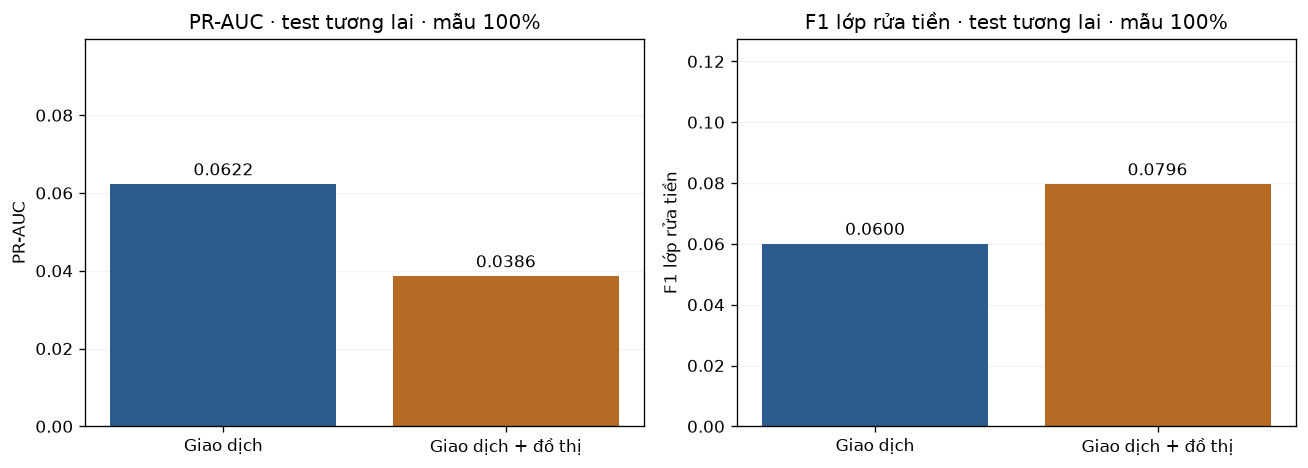

In [19]:
import matplotlib.pyplot as plt
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':10,'figure.dpi':120})
fig,axes=plt.subplots(1,2,figsize=(11,4))
labels=['Giao dịch','Giao dịch + đồ thị']
for ax,index,title in [(axes[0],5,'PR-AUC'),(axes[1],8,'F1 lớp rửa tiền')]:
    bars=ax.bar(labels,[r[index] for r in results],color=['#2b5c8f','#b56b24'])
    upper = min(1.0, max(r[index] for r in results) * 1.6)
    ax.set(ylim=(0,upper),ylabel=title,title=f'{title} · test tương lai · mẫu {AML_FRACTION:.0%}')
    ax.bar_label(bars,fmt='%.4f',padding=3)
    ax.grid(axis='y',alpha=0.15);ax.set_axisbelow(True)
plt.tight_layout();plt.show()

### Nhận xét kết quả
Với ngưỡng validation riêng (0,8 cho cơ sở, 0,9 cho đồ thị), accuracy tăng
**96,1309% → 98,4064%**, F1 tăng **0,060010 → 0,079599**.
Đồng thời PR-AUC giảm **0,062245 → 0,038593** và recall giảm
**69,8103% → 38,9509%**. Đây là đánh đổi giữa giảm cảnh báo sai và bỏ sót thêm rửa tiền.

Ngưỡng hai mô hình khác nhau nên cần xem thêm `accuracy_at_0_5` để so cùng ngưỡng mặc định.
Ở cùng ngưỡng 0,5, accuracy cơ sở là **89,7156%**, đồ thị **88,7511%**: đồ thị thấp hơn **0,9645 điểm phần trăm**. Vì vậy mức tăng accuracy ở ngưỡng riêng phản ánh cả lựa chọn ngưỡng, chưa chứng minh thêm đồ thị luôn làm tăng accuracy.
ROC-AUC/PR-AUC dùng điểm số trước ngưỡng; thay ngưỡng quyết định không làm thay đổi hai chỉ số xếp hạng này.
Kịch bản chi phí ở trên cho thấy chọn mô hình theo F1 chưa chắc tối ưu chi phí sai thực tế.

Tỷ lệ nhãn rửa tiền thay đổi giữa các tập: train **0.0992%**, validation **0.1065%**, test **0.1769%**.
Vì thế không so precision/PR-AUC giữa validation và test mà bỏ qua khác biệt tỷ lệ lớp.
So sánh cơ sở/đồ thị trong bảng chính vẫn dùng cùng các hàng test. Snapshot chỉ dùng khoảng 20% số giao dịch đầu,
không cập nhật tiếp nên sẽ cũ dần; tài khoản mới thiếu lịch sử. Kết quả chưa kiểm tra khả năng tổng quát sang ngân hàng mới.

Số liệu này thay thế bảng của lần chạy trước. Chưa đo lặp nhiều lần để định lượng dao động giữa các lượt huấn luyện;
không diễn giải chênh lệch với bản cũ thành tác dụng của việc bổ sung phần trình bày hoặc các truy vấn kiểm tra.


In [20]:
spark.stop()